# Лабораторна 3. Токенізація та трансформери

У цій лабораторній роботі ви пройдете шлях від механіки токенізації до практичного використання готових мовних моделей:

- алгоритми токенізації (BPE, WordPiece, Unigram) — натренуєте всі три на власному тексті;
- mini-GPT з нуля — повторите тренування трансформера на своєму датасеті;
- готові моделі для різних NLP-задач — класифікація, генерація, переклад, Q&A та інше через `pipeline()`;
- порівняння кількох моделей на одній задачі;
- творчий застосунок на основі готової моделі.

Демо-ноутбук лекції 4 (`transformers_demo.ipynb`) — основа для секцій 2-3, звертайтесь до нього як до довідника. Він лежить в архіві демо-матеріалів лекції 4 — посилання «Демо-матеріали (zip)» є в картці лекції на головній сторінці курсу. Розділи 1 і 4 спираються на офіційний [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/en/chapter1/1) — читайте відповідні розділи курсу перед виконанням, посилання додані в кожній секції.

## Матеріали

- [3Blue1Brown — Transformers, the tech behind LLMs](https://www.youtube.com/watch?v=wjZofJX0v4M)
- [3Blue1Brown — Attention in transformers, step-by-step](https://www.youtube.com/watch?v=eMlx5fFNoYc)
- [3Blue1Brown — How might LLMs store facts](https://www.youtube.com/watch?v=9-Jl0dxWQs8)
- [Hugging Face LLM Course — Chapter 1: Transformer Models](https://huggingface.co/learn/llm-course/en/chapter1/1)
- [Hugging Face LLM Course — Chapter 2: Using Transformers](https://huggingface.co/learn/llm-course/en/chapter2/1)
- [Hugging Face LLM Course — Chapter 6: The Tokenizers library](https://huggingface.co/learn/llm-course/en/chapter6/1)

## 0. Опрацюйте демо-ноутбук лекції 4

Прогляньте пояснення і запустіть усі клітинки демо-ноутбука.

Після цього дайте відповідь на запитання нижче.

### 0.1. Теоретичні питання (якщо потрібно дописати якийсь код, то в блоці "Мої відповіді наведіть відповідний код")

1. У розділі 2.1 демо тренер BPE отримує список окремих віршів, а не один склеєний рядок. Що б змінилось (і що б зламалось), якби ми передали один суцільний рядок?
2. З який етапів складається токенізація, поясніть сутність кожного з етапів (див. [туторіал по токенізації](https://huggingface.co/learn/llm-course/en/chapter6/8))
2. Що таке `"<unk>", "<eos>"` в 2.1.?
3. Зменшіть `VOCAB_SIZE` (2.1) удвічі-втричі (наприклад з 16000 до 4000-6000) і перетренуйте BPE-токенізатор на тому самому корпусі. Порівняйте середню кількість токенів на вірш і частку `<unk>` до/після зміни. Поясніть, чому менший словник не підвищує `<unk>`, але впливає на довжину закодованих послідовностей (а отже — і на кількість кроків, які "бачить" модель за той самий `CONTEXT_LEN`).
4. У розділі 2.2 між віршами вставлено токен `<eos>`. Навіщо? Що конкретно піде не так під час тренування mini-GPT, якщо цей роздільник прибрати?
5. Який формат мають і що репрезентують елементи тензорів `train_data` & `val_data` у розділі 2.3?
6. Допишіть в 3.2. `assert` тест, який перевіряє відповідність частин випадкового батчу.
7. У 3.3 `causal_mask` — нижньотрикутна матриця одиниць. Чому саме нижньотрикутна, а не верхньотрикутна? Що б змінилося в поведінці моделі при генерації тексту, якби маски не було?
8. У 3.10 генерація бере чекпоінт із найкращим `val_loss`, а не останній. За яких умов ці два чекпоінти збігаються, а за яких — ні? Подивіться на свою криву навчання (3.9) і скажіть, який випадок у вас.
10. Зменшіть `EVAL_INTERVAL` у 5 разів (наприклад з 250 до 50) і повторно запустіть тренування. Чи стала крива навчання (3.9) помітно гладкішою/інформативнішою? Скільки додаткового часу це коштує (частіші виклики `estimate_loss()` на `EVAL_ITERS` батчах), і чи є сенс робити `EVAL_INTERVAL` ще меншим?
11. У 4.2 той самий промпт дає дуже різний текст при `temperature=0.2` і `temperature=1.4`. Поясніть математично, що робить `temperature` з логітами перед `softmax`, і чому при дуже високій температурі текст стає майже випадковим.
12. За що саме відповідає параметр `top_p`?
13. У 4.2 змініть налаштування `enable_thinking=False` на `True` запустіть повторно клітинку і прокоментуйте зміни у результаті виконання.

### 0.2. Мої відповіді:

**1. Передавання текстів у BPE.**

Список віршів дозволяє обробляти документи окремо, без створення одного великого рядка. Якщо передати `[corpus_text]`, тренер отримає один документ: витрати пам’яті можуть зрости, а межі між віршами вже не будуть межами окремих прикладів. Сам алгоритм BPE при цьому не обов’язково зламається. Якщо ж передати безпосередньо `corpus_text`, ітератор рядка видаватиме окремі символи замість документів, що порушить навчання злиттів.

**2. Етапи токенізації.**

- Нормалізація — приведення тексту до узгодженого вигляду, наприклад нормалізація Unicode. Конкретні перетворення залежать від токенізатора.
- Попередня токенізація — початковий поділ тексту за пробілами, пунктуацією або іншими правилами.
- Застосування моделі токенізації — поділ отриманих фрагментів на токени за алгоритмом BPE, WordPiece або Unigram та визначення їхніх ID.
- Постобробка — додавання спеціальних токенів і формування кінцевої послідовності відповідно до вимог моделі.

**2. Спеціальні токени.**

`<unk>` позначає невідомий фрагмент, який токенізатор не може представити своїм словником. `<eos>` позначає кінець документа або послідовності. Саме додавання `<eos>` до словника не вставляє його між документами автоматично.

**3. Зменшення словника BPE.**

Обидва токенізатори навчено на тому самому корпусі:

| Розмір словника | Середня кількість токенів на вірш | Частка `<unk>` |
|---|---:|---:|
| 16000 | 1027.1264 | 0% |
| 6000 | 1173.3224 | 0% |

Середня довжина збільшилася приблизно на 14.2%. Менший словник містить менше довгих фрагментів, тому слова частіше розбиваються на дрібніші токени. На дослідженому корпусі потрібні базові символи представлені в обох словниках, тому частка `<unk>` не зросла. Це не гарантує відсутності `<unk>` на будь-якому новому тексті.

За CONTEXT_LEN=64 модель бачить 64 токени в обох випадках, але з меншим словником вони зазвичай охоплюють менше слів.

Код навчання окремого токенізатора:

```python
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

small_tokenizer = Tokenizer(models.BPE(unk_token="<unk>"))
small_tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(
    add_prefix_space=False
)
small_tokenizer.decoder = decoders.ByteLevel()

small_tokenizer.train_from_iterator(
    poems_df["context_poem"].dropna().tolist(),
    trainer=trainers.BpeTrainer(
        vocab_size=6000,
        special_tokens=["<unk>", "<eos>"]
    )
)
```

Повний код обчислення показників і результати наведено в доданій комірці демо-ноутбука.

**4. Роздільник між віршами.**

`<eos>` явно позначає межі документів. Без нього кінець одного вірша та початок наступного утворюють звичайний перехід у навчальній послідовності. Модель тоді навчатиметься також на таких штучних переходах і не матиме явного сигналу завершення вірша.

**5. Формат train_data та val_data.**

Це одновимірні цілочисельні тензори ID токенів у порядку їхнього розташування в корпусі. Кожен елемент — індекс токена у словнику, а не слово чи вектор embedding. Із цих послідовностей формуються випадкові вікна для навчання та валідації.

**6. Перевірка батчу.**

У демо після створення батчу додано:

```python
assert xb.shape == yb.shape == (BATCH_SIZE, CONTEXT_LEN)
assert torch.equal(xb[:, 1:], yb[:, :-1]), \
    "Помилка: таргет має бути зсунутий на один токен"
```

Перевірка підтверджує однакові розміри та відповідність перекривних частин входу й цілі зі зсувом на один токен.

**7. Причинна маска attention.**

Рядок матриці відповідає поточній позиції, стовпець — позиції, до якої вона звертається. Нижньотрикутна маска дозволяє бачити поточний і попередні токени, блокуючи майбутні.

Без маски під час навчання модель могла б бачити токени, які має передбачати. Це спричинило б витік відповіді та невідповідність умов навчання умовам генерації, де майбутні токени ще невідомі.

**8. Найкращий та останній чекпоїнти.**

Вони збігаються, якщо найменший виміряний val_loss отримано наприкінці навчання. Якщо після мінімуму валідаційна помилка зростає, найкращий чекпоїнт буде ранішим.

У початковому запуску найкращою була остання ітерація 7999, val_loss ≈ 5.6645. У запуску з EVAL_INTERVAL=50 найкращий результат отримано на ітерації 7950: 5.6477, тоді як на останній — 5.6536. Невелике зростання може бути також коливанням оцінки на випадкових батчах, тому саме по собі не доводить перенавчання.

**10. Частота оцінювання.**

Після зменшення EVAL_INTERVAL з 250 до 50 кількість оцінювань зросла з 33 до 161. Крива стала детальнішою, але не гладкішою: частіші вимірювання показали невеликі коливання втрат.

Початкове навчання тривало 6.8 хв, повторне — 10.70 хв. Різниця становила приблизно 3.9 хв, або 57%. Кожне оцінювання обробляє EVAL_ITERS=50 батчів для train і стільки ж для val.

Для повторного запуску створено нову модель та оптимізатор, а в циклі використано:

```python
if it % 50 == 0 or it == MAX_ITERS - 1:
    losses = estimate_loss_eval50()
```

Повний код, окремий чекпоїнт і графік порівняння наведено в демо. Ініціалізація запусків відрізнялася, тому різницю val_loss не можна приписати лише EVAL_INTERVAL. На час також могли вплинути умови виконання. Ще менший інтервал збільшив би витрати, тоді як загальну тенденцію вже добре видно.

**11. Температура.**

Перед softmax логіти діляться на температуру T:

p_i = exp(z_i / T) / sum_j exp(z_j / T).

За T=0.2 розподіл стає гострішим: найбільш імовірні токени отримують більшу перевагу. За T=1.4 він стає рівномірнішим, і менш імовірні токени вибираються частіше. За дуже високої температури розподіл наближається до рівномірного до застосування інших фільтрів, що може погіршувати зв’язність тексту.

**12. Параметр top_p.**

Top_p залишає найменший набір найімовірніших токенів, сумарна ймовірність яких досягає заданого порога. Вибір наступного токена виконується серед цього набору після перенормування ймовірностей. Менший top_p сильніше обмежує вибір, більший допускає більше варіантів.

У демо temperature і top_p змінювалися одночасно, тому спостерігався їхній спільний вплив.

**13. Режим enable_thinking.**

Після заміни `enable_thinking=False` на `True` з’явився блок `<think>` з англомовними міркуваннями про запит. За ліміту max_new_tokens=300 завершеного продовження історії не отримано: доступний бюджет було витрачено на міркування. Також спостерігалася плутанина щодо назви міста. Отже, ввімкнення цього режиму саме по собі не гарантує правильності.

Змінений виклик:

```python
text = hf_tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True,
    enable_thinking=True
)
```

---
## 1. Свій датасет

Знайдіть **свій** українськомовний текстовий корпус, достатній за обсягом для mini-GPT — наприклад, на [Hugging Face Datasets](https://huggingface.co/datasets?language=language:uk) або на [Kaggle](https://www.kaggle.com/datasets?search=ukrainian). Жанр і епоха — на ваш вибір (новини, художня література, вікіпедія, форуми, судові рішення тощо), головне — одна мова (українська) і достатньо тексту, щоб токенізатор і модель побачили бодай прості закономірності.

⚠️ Якщо датасет великий (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`), інакше отримаєте помилку нестачі пам'яті (out of memory, OOM).

⚠️ Якщо датасет доступний лише через `streaming=True` (наприклад, через розмір) — `load_dataset(..., streaming=True).take(N)` повертає `IterableDataset`, у якого **нема** `.to_pandas()` і `len()`. Спершу матеріалізуйте вибірку в список, а вже потім — у `DataFrame`:
```python
rows = list(streamed_ds)
poems_df = pd.DataFrame(rows)
```

In [1]:
!pip install -q datasets tokenizers pandas "transformers[sentencepiece]==5.18.0"

In [2]:
from datasets import load_dataset
import pandas as pd
import re

DATASET_ID = "Goader/ukrainian-news-2026"

stream = load_dataset(
    DATASET_ID,
    "deduplicated",
    split="train",
    streaming=True
)

# Беремо до 10 000 документів, не завантажуючи весь датасет
rows = [
    {"text": row["text"]}
    for row in stream.take(10_000)
    if isinstance(row.get("text"), str)
]

texts_df = pd.DataFrame(rows, columns=["text"])

texts_df["text"] = texts_df["text"].map(
    lambda text: re.sub(r"\s+", " ", text).strip()
)

texts_df = (
    texts_df[texts_df["text"].str.len() >= 200]
    .drop_duplicates(subset="text")
    .reset_index(drop=True)
)

documents = texts_df["text"].tolist()
assert documents, "Не отримано текстів із датасету"

corpus_text = "\n\n".join(documents)

print("Датасет:", DATASET_ID)
print("Документів:", len(documents))
print("Символів:", f"{len(corpus_text):,}")
print("Слів:", f"{sum(len(text.split()) for text in documents):,}")
print("\nПриклад тексту:\n")
print(documents[0][:1200])

README.md:   0%|          | 0.00/11.9k [00:00<?, ?B/s]

Датасет: Goader/ukrainian-news-2026
Документів: 9999
Символів: 22,520,522
Слів: 3,170,827

Приклад тексту:

давні магічні символи приховані у візерунках Традиція вишивати сорочки в Україні має історію, яка починається ще у дохристиянські часи. Найдавніші вишиванки мали магічний сенс - вони були оберегами, причому це значення збереглося і після поширення християнства. Вишивання вважалося ритуалом, а символи, зображені на візерунках вишиванки, мали магічне значення. коло Фото: folkmoda.net Один із найдавніших язичницьких символів сонця, що означає божественну життєву енергію, безперервність буття та вічність. Крім того, коло з точкою всередині може символізувати центр світобудови. Також коло може бути символом божественної чистоти і асоціюватися з вінком нареченої. Один із найдавніших язичницьких символів сонця, що означає божественну життєву енергію, безперервність буття та вічність. Також коло може бути символом божественної чистоти та асоціюватися з вінком нареченої. Квадрат Фото: fol

Для роботи обрано корпус українськомовних новин Goader/ukrainian-news-2026, підмножину deduplicated, колонку text. Завантажено перші 10 000 записів потоковим способом. Після нормалізації пробілів, вилучення коротких текстів і точних дублікатів залишилося 9999 документів: 22 520 522 символи та 3 170 827 слів. На відміну від поезії в демо, цей корпус містить публіцистичні тексти.

---
## 2. Токенізатори: BPE, WordPiece, Unigram

Демо тренує лише BPE. У цій секції ви натренуєте й порівняєте всі три основні алгоритми токенізації на **своєму** тексті.

Матеріал — офіційний [Hugging Face LLM Course, розділ 6](https://huggingface.co/learn/llm-course/en/chapter6/1). Пройдіть і повторіть на своїх даних:

1. **[6.2. Тренування нового токенізатора на основі старого](https://huggingface.co/learn/llm-course/en/chapter6/2)** — найпростіший шлях: `tokenizer.train_new_from_iterator(...)` на основі архітектури готового токенізатора (наприклад, `Qwen/Qwen2.5-0.5B-Instruct`). Зробіть це як розминку перед ручними варіантами нижче.
2. **[6.5. Алгоритм BPE](https://huggingface.co/learn/llm-course/en/chapter6/5)** — повторіть покрокову реалізацію з туторіалу на своєму тексті, повністю вручну або за допомогою бібліотеки `tokenizers`.
3. **[6.6. Алгоритм WordPiece](https://huggingface.co/learn/llm-course/en/chapter6/6)** — так само.
4. **[6.7. Алгоритм Unigram](https://huggingface.co/learn/llm-course/en/chapter6/7)** — так само.

### 1.1. Порівняння

Для однакового `vocab_size` (візьміть, наприклад, 500 — на невеликому зразку тексту більший словник не встигне показати різницю) порівняйте три токенізатори в невеликій таблиці: розмір словника, кількість токенів на вашому зразку, скільки токенів виходить на кількох обраних словах (частотне й рідкісне — як у лекції). Коротко письмово: який алгоритм дав найкоротші послідовності на вашому тексті і чи це узгоджується з тим, що каже туторіал про природу кожного алгоритму?

In [3]:
from transformers import AutoTokenizer

base_tokenizer = AutoTokenizer.from_pretrained(
    "Qwen/Qwen2.5-0.5B-Instruct"
)

# Для порівняння токенізаторів беремо однаковий невеликий корпус
tokenizer_train_texts = documents[:1000]

def text_batches(texts, batch_size=100):
    for start in range(0, len(texts), batch_size):
        yield texts[start:start + batch_size]

warmup_tokenizer = base_tokenizer.train_new_from_iterator(
    text_batches(tokenizer_train_texts),
    vocab_size=500
)

sample_text = (
    "Українські студенти досліджують штучний інтелект "
    "та створюють нові технології."
)

print("Фактичний розмір словника:", len(warmup_tokenizer))
print("Текст:", sample_text)
print("Токени:", warmup_tokenizer.tokenize(sample_text))
print(
    "Кількість токенів:",
    len(warmup_tokenizer.encode(
        sample_text, add_special_tokens=False
    ))
)

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Фактичний розмір словника: 508
Текст: Українські студенти досліджують штучний інтелект та створюють нові технології.
Токени: ['Ð', '£', 'ÐºÑĢÐ°ÑĹ', 'Ð½', 'ÑģÑĮÐº', 'Ñĸ', 'ĠÑģÑĤ', 'Ñĥ', 'Ð´', 'ÐµÐ½', 'ÑĤÐ¸', 'ĠÐ´', 'Ð¾Ñģ', 'Ð»', 'ÑĸÐ´', 'Ð¶', 'Ñĥ', 'Ñİ', 'ÑĤÑĮ', 'ĠÑ', 'Ī', 'ÑĤ', 'Ñĥ', 'Ñĩ', 'Ð½Ð¸Ð¹', 'ĠÑĸÐ½', 'ÑĤ', 'ÐµÐ»', 'ÐµÐº', 'ÑĤ', 'ĠÑĤÐ°', 'ĠÑģÑĤ', 'Ð²', 'Ð¾ÑĢ', 'Ñİ', 'Ñİ', 'ÑĤÑĮ', 'ĠÐ½', 'Ð¾Ð²', 'Ñĸ', 'ĠÑĤ', 'Ðµ', 'Ñħ', 'Ð½', 'Ð¾Ð»', 'Ð¾Ð³', 'ÑĸÑĹ', '.']
Кількість токенів: 48


In [4]:
from tokenizers import (
    Tokenizer, models, trainers,
    pre_tokenizers, normalizers, decoders
)

COMPARE_VOCAB_SIZE = 500
SPECIAL_TOKENS = ["<unk>", "<eos>"]

def prepare_tokenizer(model):
    tokenizer = Tokenizer(model)
    tokenizer.normalizer = normalizers.NFC()
    tokenizer.pre_tokenizer = pre_tokenizers.Whitespace()
    return tokenizer

bpe = prepare_tokenizer(models.BPE(unk_token="<unk>"))
bpe.train_from_iterator(
    tokenizer_train_texts,
    trainer=trainers.BpeTrainer(
        vocab_size=COMPARE_VOCAB_SIZE,
        special_tokens=SPECIAL_TOKENS
    )
)

wordpiece = prepare_tokenizer(models.WordPiece(unk_token="<unk>"))
wordpiece.decoder = decoders.WordPiece(prefix="##")
wordpiece.train_from_iterator(
    tokenizer_train_texts,
    trainer=trainers.WordPieceTrainer(
        vocab_size=COMPARE_VOCAB_SIZE,
        special_tokens=SPECIAL_TOKENS
    )
)

unigram = prepare_tokenizer(models.Unigram())
unigram.train_from_iterator(
    tokenizer_train_texts,
    trainer=trainers.UnigramTrainer(
        vocab_size=COMPARE_VOCAB_SIZE,
        special_tokens=SPECIAL_TOKENS,
        unk_token="<unk>"
    )
)

comparison_tokenizers = {
    "BPE": bpe,
    "WordPiece": wordpiece,
    "Unigram": unigram
}

comparison_rows = []

for name, tokenizer in comparison_tokenizers.items():
    encoded = tokenizer.encode(sample_text)

    comparison_rows.append({
        "Алгоритм": name,
        "Розмір словника": tokenizer.get_vocab_size(),
        "Токенів у реченні": len(encoded.ids),
        "Кількість <unk>": encoded.ids.count(
            tokenizer.token_to_id("<unk>")
        )
    })

display(pd.DataFrame(comparison_rows))

,Алгоритм,Розмір словника,Токенів у реченні,Кількість <unk>
0,BPE,500,32,0
1,WordPiece,500,44,0
2,Unigram,500,39,0


In [5]:
from collections import Counter

word_counts = Counter(
    word.lower()
    for text in tokenizer_train_texts
    for word in re.findall(
        r"[А-Яа-яІіЇїЄєҐґ]+(?:[’'-][А-Яа-яІіЇїЄєҐґ]+)*",
        text
    )
)

# Беремо слова довжиною від 6 літер
frequent_word = next(
    word for word, count in word_counts.most_common()
    if len(word) >= 6
)

rare_word = next(
    word for word, count in sorted(word_counts.items())
    if count == 1 and len(word) >= 10
)

word_rows = []

for category, word in [
    ("Частотне", frequent_word),
    ("Рідкісне", rare_word)
]:
    for name, tokenizer in comparison_tokenizers.items():
        encoded = tokenizer.encode(word)

        word_rows.append({
            "Тип": category,
            "Слово": word,
            "Частота в корпусі": word_counts[word],
            "Алгоритм": name,
            "Кількість токенів": len(encoded.ids),
            "Токени": " | ".join(encoded.tokens)
        })

word_comparison_df = pd.DataFrame(word_rows)
display(word_comparison_df)

,Тип,Слово,Частота в корпусі,Алгоритм,Кількість токенів,Токени
0,Частотне,україни,1419,BPE,3,у | краї | ни
1,Частотне,україни,1419,WordPiece,3,у | ##краї | ##ни
2,Частотне,україни,1419,Unigram,3,у | країн | и
3,Рідкісне,абдольнассера,1,BPE,8,а | б | до | ль | на | с | се | ра
4,Рідкісне,абдольнассера,1,WordPiece,10,а | ##б | ##д | ##ол | ##ь | ##на | ##с | ##с ...
5,Рідкісне,абдольнассера,1,Unigram,8,а | б | до | ль | на | с | се | ра


Токенізатори BPE, WordPiece та Unigram навчено на однакових 1000 документах зі словником 500 токенів, нормалізацією NFC та однаковою попередньою токенізацією.

На тестовому реченні BPE дав 32 токени, Unigram — 39, WordPiece — 44. Невідомих токенів у реченні не виявлено. Слово «україни», яке зустрілося 1419 разів у навчальній вибірці, усі алгоритми розбили на 3 токени. Рідкісне слово «абдольнассера» з одним входженням BPE та Unigram розбили на 8 токенів, WordPiece — на 10.

Найкоротшу послідовність на тестовому реченні отримано за допомогою BPE. Це узгоджується з використанням частотних злиттів у BPE. WordPiece обирає злиття за іншим критерієм, а Unigram використовує ймовірнісну модель сегментації. Результат залежить від корпусу, розміру словника та конкретного тексту, тому універсального переможця це порівняння не визначає.

---
## 3. mini-GPT на своїх даних

Повторіть підхід із розділів 2-3 демо-ноутбука на своєму датасеті — не копіюйте код один в один: у вашого датасету інша колонка з текстом, інший обсяг, інший жанр/регістр мови — токенізатор і модель побачать зовсім інші закономірності, ніж на поезії з демо.

### 3.1. Корпус і токенізація

1. Завантажте свій датасет і зберіть `corpus_text` з потрібної колонки (демо 1.2).
2. Натренуйте токенізатор на своєму корпусі (демо 2.1). **Якщо ваш датасет великий** (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`). Не забудьте `<eos>` між документами (демо 2.2).
3. Спліт train/val (демо 2.3).

### 3.2. Модель: щонайменше 2 варіанти

За зразком розділу 3 демо (`AttentionHead`, `MultiHeadAttention`, `TransformerBlock`, `MiniGPT`) — тренуйте щонайменше 2 варіанти, які відрізняються параметрами: інший `VOCAB_SIZE`, інша `CONTEXT_LEN`, інша кількість шарів/голів (`N_LAYERS`/`N_HEADS`), або інший `MAX_ITERS`. Кожен варіант логуйте в TensorBoard в окрему підпапку (як у демо 3.8), з осмисленою назвою.

### 3.3. Генерація і висновки

Для кожного варіанта — генерація на найкращому за `val_loss` чекпоінті (демо 3.10), той самий промпт для всіх варіантів, щоб порівняння було чесним. Коротко письмово: який варіант дав кращий `val_loss` і чи помітно це за якістю згенерованого тексту? Що саме (зміна словника, глибини мережі, довжини контексту) дало найбільший ефект?

In [6]:
import random
import numpy as np
from tokenizers import (
    Tokenizer, models, trainers, pre_tokenizers, decoders
)

SEED = 42
GPT_VOCAB_SIZE = 8000

# Перемішуємо копію списку для відтворюваного поділу
shuffled_documents = documents.copy()
random.Random(SEED).shuffle(shuffled_documents)

split_index = int(0.9 * len(shuffled_documents))
train_documents = shuffled_documents[:split_index]
val_documents = shuffled_documents[split_index:]

gpt_tokenizer = Tokenizer(models.BPE(unk_token="<unk>"))
gpt_tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(
    add_prefix_space=False
)
gpt_tokenizer.decoder = decoders.ByteLevel()

gpt_tokenizer.train_from_iterator(
    train_documents,
    trainer=trainers.BpeTrainer(
        vocab_size=GPT_VOCAB_SIZE,
        special_tokens=["<unk>", "<eos>"],
        initial_alphabet=pre_tokenizers.ByteLevel.alphabet()
    )
)

EOS_ID = gpt_tokenizer.token_to_id("<eos>")

def encode_documents(texts, batch_size=128):
    chunks = []

    for start in range(0, len(texts), batch_size):
        encodings = gpt_tokenizer.encode_batch(
            texts[start:start + batch_size]
        )

        batch_ids = []
        for encoding in encodings:
            batch_ids.extend(encoding.ids)
            batch_ids.append(EOS_ID)

        chunks.append(np.asarray(batch_ids, dtype=np.int32))

    return np.concatenate(chunks)

train_ids = encode_documents(train_documents)
val_ids = encode_documents(val_documents)

print("Розмір словника:", gpt_tokenizer.get_vocab_size())
print("Train документів:", len(train_documents))
print("Val документів:", len(val_documents))
print("Train токенів:", f"{len(train_ids):,}")
print("Val токенів:", f"{len(val_ids):,}")
print("Тип масивів:", train_ids.dtype)
print(
    "Пам’ять масивів:",
    f"{(train_ids.nbytes + val_ids.nbytes) / 1024**2:.2f} МіБ"
)

assert train_ids[-1] == EOS_ID
assert val_ids[-1] == EOS_ID
assert train_ids.min() >= 0
assert val_ids.min() >= 0
assert train_ids.max() < gpt_tokenizer.get_vocab_size()
assert val_ids.max() < gpt_tokenizer.get_vocab_size()

print("Перевірки пройдено")

Розмір словника: 8000
Train документів: 8999
Val документів: 1000
Train токенів: 5,222,637
Val токенів: 559,322
Тип масивів: int32
Пам’ять масивів: 22.06 МіБ
Перевірки пройдено


In [7]:
import os
import json
import random
import numpy as np
import torch

from google.colab import drive
drive.mount("/content/drive")

ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab3"
MODELS_DIR = os.path.join(ARTIFACT_DIR, "models")
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")

os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(RUNS_DIR, exist_ok=True)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()

# Корпус лишаємо на CPU в компактному форматі int32.
# Батчі перед передаванням моделі перетворюватимемо на long.
train_data = torch.from_numpy(train_ids)
val_data = torch.from_numpy(val_ids)

gpt_tokenizer.save(
    os.path.join(MODELS_DIR, "news_bpe_8000.json")
)

with open(
    os.path.join(ARTIFACT_DIR, "corpus_info.json"),
    "w", encoding="utf-8"
) as f:
    json.dump({
        "dataset": DATASET_ID,
        "seed": SEED,
        "train_documents": len(train_documents),
        "val_documents": len(val_documents),
        "train_tokens": len(train_ids),
        "val_tokens": len(val_ids),
        "vocab_size": gpt_tokenizer.get_vocab_size()
    }, f, ensure_ascii=False, indent=2)

print("Пристрій:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

print("Папка результатів:", ARTIFACT_DIR)
print("Токенізатор збережено")

Mounted at /content/drive
Пристрій: cuda
GPU: Tesla T4
Папка результатів: /content/drive/MyDrive/ai_systems/lab3
Токенізатор збережено


In [8]:
import torch.nn as nn
import torch.nn.functional as F

class AttentionHead(nn.Module):
    def __init__(self, embed_dim, head_dim, context_len, dropout):
        super().__init__()
        self.key = nn.Linear(embed_dim, head_dim, bias=False)
        self.query = nn.Linear(embed_dim, head_dim, bias=False)
        self.value = nn.Linear(embed_dim, head_dim, bias=False)
        self.register_buffer(
            "causal_mask",
            torch.tril(torch.ones(context_len, context_len))
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        length = x.shape[1]
        k = self.key(x)
        q = self.query(x)

        scores = (q @ k.transpose(-2, -1)) * k.shape[-1] ** -0.5
        scores = scores.masked_fill(
            self.causal_mask[:length, :length] == 0,
            float("-inf")
        )
        weights = self.dropout(F.softmax(scores, dim=-1))
        return weights @ self.value(x)


class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim, n_heads, context_len, dropout):
        super().__init__()
        assert embed_dim % n_heads == 0
        self.heads = nn.ModuleList([
            AttentionHead(
                embed_dim, embed_dim // n_heads, context_len, dropout
            )
            for _ in range(n_heads)
        ])
        self.projection = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        combined = torch.cat([head(x) for head in self.heads], dim=-1)
        return self.dropout(self.projection(combined))


class TransformerBlock(nn.Module):
    def __init__(self, embed_dim, n_heads, context_len, dropout):
        super().__init__()
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.attention = MultiHeadAttention(
            embed_dim, n_heads, context_len, dropout
        )
        self.feedforward = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim),
            nn.GELU(),
            nn.Linear(4 * embed_dim, embed_dim),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        return x + self.feedforward(self.norm2(x))


class MiniGPT(nn.Module):
    def __init__(
        self, vocab_size, embed_dim, n_heads,
        n_layers, context_len, dropout
    ):
        super().__init__()
        self.context_len = context_len
        self.token_embedding = nn.Embedding(vocab_size, embed_dim)
        self.position_embedding = nn.Embedding(context_len, embed_dim)

        self.blocks = nn.Sequential(*[
            TransformerBlock(
                embed_dim, n_heads, context_len, dropout
            )
            for _ in range(n_layers)
        ])
        self.final_norm = nn.LayerNorm(embed_dim)
        self.output = nn.Linear(embed_dim, vocab_size)

    def forward(self, ids, targets=None):
        length = ids.shape[1]
        positions = torch.arange(length, device=ids.device)

        x = self.token_embedding(ids) + self.position_embedding(positions)
        logits = self.output(self.final_norm(self.blocks(x)))

        loss = None
        if targets is not None:
            loss = F.cross_entropy(
                logits.reshape(-1, logits.shape[-1]),
                targets.reshape(-1)
            )
        return logits, loss

    @torch.no_grad()
    def generate(self, ids, max_new_tokens=100, temperature=0.8, top_k=40):
        for _ in range(max_new_tokens):
            logits, _ = self(ids[:, -self.context_len:])
            logits = logits[:, -1, :] / temperature

            if top_k is not None:
                values, _ = torch.topk(
                    logits, min(top_k, logits.shape[-1])
                )
                logits = logits.masked_fill(
                    logits < values[:, [-1]], float("-inf")
                )

            next_id = torch.multinomial(
                F.softmax(logits, dim=-1), num_samples=1
            )
            ids = torch.cat([ids, next_id], dim=1)

        return ids


# Варіанти відрізнятимуться лише кількістю блоків
model_configs = {
    "minigpt_v1": {
        "vocab_size": gpt_tokenizer.get_vocab_size(),
        "embed_dim": 128,
        "n_heads": 4,
        "n_layers": 2,
        "context_len": 64,
        "dropout": 0.1
    },
    "minigpt_v2": {
        "vocab_size": gpt_tokenizer.get_vocab_size(),
        "embed_dim": 128,
        "n_heads": 4,
        "n_layers": 4,
        "context_len": 64,
        "dropout": 0.1
    }
}

# Коротка перевірка форми виходу та обчислення loss
for name, config in model_configs.items():
    set_seed()
    check_model = MiniGPT(**config).to(device)
    x = train_data[:65].long().to(device)
    logits, loss = check_model(x[:-1][None, :], x[1:][None, :])

    assert logits.shape == (1, 64, config["vocab_size"])
    assert torch.isfinite(loss)

    print(
        name,
        "| параметрів:", f"{sum(p.numel() for p in check_model.parameters()):,}",
        "| loss:", round(loss.item(), 4)
    )
    del check_model, x, logits, loss

print("Перевірку моделей пройдено")

minigpt_v1 | параметрів: 2,460,224 | loss: 9.0512
minigpt_v2 | параметрів: 2,856,000 | loss: 9.2177
Перевірку моделей пройдено


In [9]:
import gc
import time
from torch.utils.tensorboard import SummaryWriter

BATCH_SIZE = 64
MAX_ITERS = 8000
LEARNING_RATE = 3e-4
EVAL_INTERVAL = 250
EVAL_ITERS = 30

def get_batch(source, context_len, generator):
    starts = torch.randint(
        len(source) - context_len,
        (BATCH_SIZE,),
        generator=generator
    )

    x = torch.stack([
        source[i:i + context_len] for i in starts.tolist()
    ])
    y = torch.stack([
        source[i + 1:i + context_len + 1]
        for i in starts.tolist()
    ])

    return x.long().to(device), y.long().to(device)


@torch.no_grad()
def evaluate_model(model, context_len):
    model.eval()
    result = {}

    # Однакові контрольні батчі для обох моделей
    for split, source in [
        ("train", train_data),
        ("val", val_data)
    ]:
        generator = torch.Generator().manual_seed(
            SEED + (100 if split == "train" else 200)
        )
        losses = []

        for _ in range(EVAL_ITERS):
            x, y = get_batch(source, context_len, generator)
            _, loss = model(x, y)
            losses.append(loss.item())

        result[split] = sum(losses) / len(losses)

    model.train()
    return result


gpt_histories = {}
gpt_results = []

for name, config in model_configs.items():
    set_seed(SEED)
    model = MiniGPT(**config).to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LEARNING_RATE
    )
    train_generator = torch.Generator().manual_seed(SEED)

    writer = SummaryWriter(
        log_dir=os.path.join(RUNS_DIR, name)
    )
    checkpoint_path = os.path.join(MODELS_DIR, f"{name}.pt")

    history = {"iteration": [], "train": [], "val": []}
    best_val = float("inf")
    best_iteration = None
    parameter_count = sum(p.numel() for p in model.parameters())

    print(f"\n=== Навчання {name} ===", flush=True)
    if device.type == "cuda":
        torch.cuda.synchronize()
    started = time.perf_counter()

    try:
        for iteration in range(MAX_ITERS):
            model.train()
            x, y = get_batch(
                train_data, config["context_len"], train_generator
            )
            _, loss = model(x, y)

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()

            if (
                iteration % EVAL_INTERVAL == 0
                or iteration == MAX_ITERS - 1
            ):
                scores = evaluate_model(
                    model, config["context_len"]
                )

                history["iteration"].append(iteration)
                history["train"].append(scores["train"])
                history["val"].append(scores["val"])

                writer.add_scalar(
                    "Loss/train", scores["train"], iteration
                )
                writer.add_scalar(
                    "Loss/val", scores["val"], iteration
                )

                if scores["val"] < best_val:
                    best_val = scores["val"]
                    best_iteration = iteration

                    torch.save(
                        model.state_dict(), checkpoint_path
                    )

                print(
                    f"iter {iteration:4d}: "
                    f"train={scores['train']:.4f}, "
                    f"val={scores['val']:.4f}",
                    flush=True
                )
    finally:
        writer.close()

    if device.type == "cuda":
        torch.cuda.synchronize()
    elapsed_minutes = (time.perf_counter() - started) / 60

    gpt_histories[name] = history
    gpt_results.append({
        "section": "mini_gpt",
        "model": name,
        "n_layers": config["n_layers"],
        "parameters": parameter_count,
        "best_iteration": best_iteration,
        "val_loss": best_val,
        "training_minutes": elapsed_minutes
    })

    with open(
        os.path.join(MODELS_DIR, f"{name}_config.json"),
        "w", encoding="utf-8"
    ) as f:
        json.dump(config, f, indent=2)

    with open(
        os.path.join(ARTIFACT_DIR, f"{name}_history.json"),
        "w", encoding="utf-8"
    ) as f:
        json.dump(history, f, indent=2)

    # Зберігаємо таблицю після кожної завершеної моделі
    pd.DataFrame(gpt_results).to_csv(
        os.path.join(ARTIFACT_DIR, "results.csv"), index=False
    )

    print(
        f"Завершено {name}: best val={best_val:.4f}, "
        f"ітерація={best_iteration}, час={elapsed_minutes:.2f} хв"
    )

    del model, optimizer, x, y, loss
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()

display(pd.DataFrame(gpt_results).round(4))


=== Навчання minigpt_v1 ===
iter    0: train=9.1295, val=9.1296
iter  250: train=7.5178, val=7.5273
iter  500: train=7.2559, val=7.2693
iter  750: train=6.8708, val=6.8926
iter 1000: train=6.5284, val=6.5533
iter 1250: train=6.2565, val=6.2886
iter 1500: train=6.0385, val=6.0809
iter 1750: train=5.8641, val=5.9062
iter 2000: train=5.7206, val=5.7698
iter 2250: train=5.6037, val=5.6571
iter 2500: train=5.5065, val=5.5653
iter 2750: train=5.4222, val=5.4873
iter 3000: train=5.3485, val=5.4164
iter 3250: train=5.2858, val=5.3611
iter 3500: train=5.2291, val=5.3065
iter 3750: train=5.1802, val=5.2597
iter 4000: train=5.1346, val=5.2195
iter 4250: train=5.0936, val=5.1827
iter 4500: train=5.0546, val=5.1465
iter 4750: train=5.0214, val=5.1145
iter 5000: train=4.9893, val=5.0832
iter 5250: train=4.9619, val=5.0648
iter 5500: train=4.9328, val=5.0343
iter 5750: train=4.9089, val=5.0153
iter 6000: train=4.8847, val=4.9927
iter 6250: train=4.8619, val=4.9737
iter 6500: train=4.8397, val=4.9530

,section,model,n_layers,parameters,best_iteration,val_loss,training_minutes
0,mini_gpt,minigpt_v1,2,2460224,7999,4.8565,3.0383
1,mini_gpt,minigpt_v2,4,2856000,7999,4.6913,4.8027


In [10]:
PROMPT = "Сьогодні в Україні"
generation_rows = []

for name, config in model_configs.items():
    model = MiniGPT(**config).to(device)

    model.load_state_dict(torch.load(
        os.path.join(MODELS_DIR, f"{name}.pt"),
        map_location=device,
        weights_only=True
    ))
    model.eval()

    prompt_ids = torch.tensor(
        [gpt_tokenizer.encode(PROMPT).ids],
        dtype=torch.long,
        device=device
    )

    # Однаковий seed і параметри генерації
    set_seed(SEED)
    generated_ids = model.generate(
        prompt_ids,
        max_new_tokens=120,
        temperature=0.8,
        top_k=40
    )

    text = gpt_tokenizer.decode(
        generated_ids[0].tolist(),
        skip_special_tokens=True
    )

    generation_rows.append({"model": name, "text": text})

    print(f"\n=== {name} ===")
    print(text)

    del model, prompt_ids, generated_ids
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()

with open(
    os.path.join(ARTIFACT_DIR, "generation_comparison.json"),
    "w", encoding="utf-8"
) as f:
    json.dump(
        generation_rows, f, ensure_ascii=False, indent=2
    )


=== minigpt_v1 ===
Сьогодні в Україні в одному з початку повномасштабної війни. Про це він провів зустріч із посиланням на брифінгу. «Подив до "Слуги, яким будуть використало на посаді очільника ОПКартнер безпеки України, які стосовно у Венесуелі та його словами, а також у Венесуелі. У разі майбутнього ураження, а також зауважити, що вони не тільки про це. За даними видання RG-казму, що для Кремля в Україні не проводять з'являлася в інших містах, а й інші, які мали складається на території України. У відповідь за межами України. Як повідомляли

=== minigpt_v2 ===
Сьогодні в Україні в одному з'являлася. "Це не було прогнози, а не бачив на чоловічному рівні". У цьому проєкті це була проблема. Він також є одним із заявами, хто шукає у тому, що вони можуть бути боксерти. Саме тому ми писали, що, чому це вже було, що вони не тільки у реальному кабінеті знянами по всій Україні, що для них були впевнено. Два не буде занадто сильно… З Новим роком. У разі не варто звернути на те, що вона може 

Порівняно два варіанти mini-GPT з однаковим словником 8000 токенів, контекстом 64, розмірністю embedding 128 та чотирма attention-головами. Змінювалася кількість блоків: 2 у v1 та 4 у v2. Обидві моделі навчалися 8000 ітерацій.

Найкращий val_loss моделі v1 становив 4.8565, моделі v2 — 4.6913, тобто приблизно на 3.4% менше. Час навчання збільшився з 3.04 до 4.80 хв. В обох випадках найкращим став останній оцінений чекпоїнт.

За однакового промпту та параметрів генерації обидві моделі відтворювали окремі риси новинного стилю, проте припускалися граматичних і змістових помилок. На цьому прикладі явної переваги v2 за зв’язністю тексту не видно. Збільшення глибини покращило валідаційну втрату; вплив інших параметрів у цьому експерименті не досліджувався.

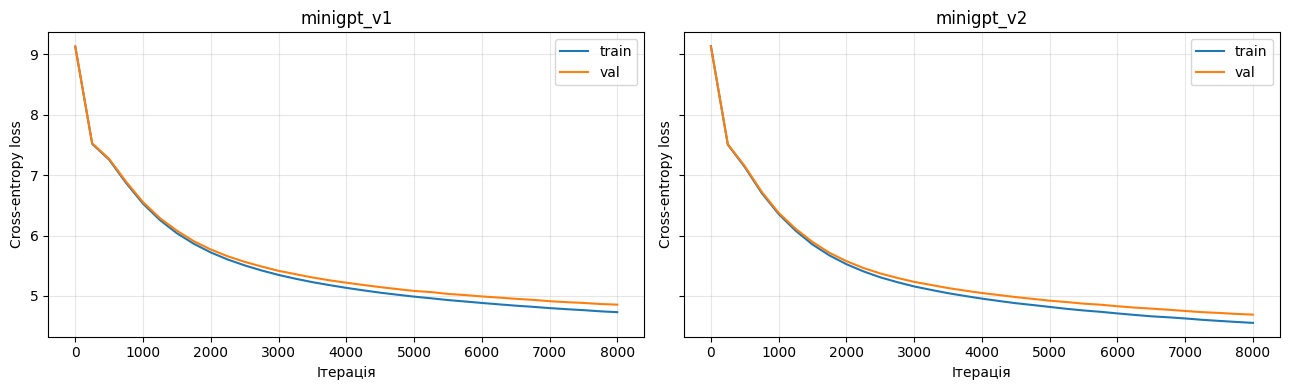

In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)

for ax, (name, history) in zip(axes, gpt_histories.items()):
    ax.plot(history["iteration"], history["train"], label="train")
    ax.plot(history["iteration"], history["val"], label="val")
    ax.set_title(name)
    ax.set_xlabel("Ітерація")
    ax.set_ylabel("Cross-entropy loss")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.savefig(
    os.path.join(ARTIFACT_DIR, "minigpt_learning_curves.png"),
    dpi=200,
    bbox_inches="tight"
)
plt.show()

---
## 4. Playground готових моделей

Тур по задачах через `pipeline()` — на основі [HF LLM Course, Chapter 1, §3](https://huggingface.co/learn/llm-course/en/chapter1/3).

_Зверніть увагу_: в межах попередніх завдань Ви могли завантажити памʼять "під завʼязку", тому для безпроблемного виконання наступних секцій вивільніть памʼять:

1. **Спершу збережіть усе потрібне на диск** — чекпоінти mini-GPT (`models/minigpt_v*.pt`), токенізатори, `results.csv`. Секції 4-6 від змінних секцій 1-3 не залежать, тож після цього їх можна сміливо видаляти.
2. **Видаліть великі обʼєкти** — моделі, оптимізатори, тензори `train_data`/`val_data`, корпус і `DataFrame`-и — і зберіть сміття:
   ```python
   import gc, torch

   del model, optimizer, train_data, val_data, corpus_text  # підставте свої імена змінних
   gc.collect()
   if torch.cuda.is_available():
       torch.cuda.empty_cache()
       print(f"GPU: зайнято {torch.cuda.memory_allocated() / 1e9:.2f} GB")
   ```
   Памʼять звільниться лише тоді, коли на обʼєкт не лишиться **жодного** посилання: зверніть увагу на копії в інших змінних, списках і словниках (наприклад, словник із кількома варіантами моделей).
3. **Перевірте, що памʼять справді звільнилась**: індикатор RAM/GPU вгорі праворуч.
4. **У самій секції 4 не тримайте всі pipeline-и одночасно**: кожен `pipeline(...)` завантажує окрему модель. Перевикористовуйте одну змінну (як `classifier` нижче) або робіть `del` + `gc.collect()` після кожної задачі.
5. **Стежте за диском**: моделі кешуються в `~/.cache/huggingface/hub`, і кілька моделей для summarization/translation легко займуть кілька ГБ. Переглянути й почистити кеш: `hf cache ls` / `hf cache rm <id моделі>`.

In [12]:
import gc

# Перевіряємо збережені результати
for filename in [
    "minigpt_v1.pt",
    "minigpt_v2.pt",
    "news_bpe_8000.json"
]:
    path = os.path.join(MODELS_DIR, filename)
    assert os.path.isfile(path), f"Не знайдено: {path}"

assert os.path.isfile(os.path.join(ARTIFACT_DIR, "results.csv"))

gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(
        "GPU: зайнято",
        f"{torch.cuda.memory_allocated() / 1e9:.2f} ГБ"
    )

print("Моделі, токенізатор і results.csv збережено")

GPU: зайнято 0.17 ГБ
Моделі, токенізатор і results.csv збережено


### 4.0. Запустіть приклади виконання різних NLP задач

In [13]:
!pip install "transformers[sentencepiece]==5.18.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 42.4 MB/s  0:00:00
  Attempting uninstall: transformers
    Found existing installation: transformers 5.22.1
    Uninstalling transformers-5.22.1:
      Successfully uninstalled transformers-5.22.1


In [1]:
# Sentiment analysis
from transformers import pipeline

classifier = pipeline("sentiment-analysis")
print(classifier("I've been waiting for a HuggingFace course my whole life."))
print(classifier(
    ["I've been waiting for a HuggingFace course my whole life.", "I hate this so much!"]
))

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

[{'label': 'POSITIVE', 'score': 0.9598046541213989}]
[{'label': 'POSITIVE', 'score': 0.9598046541213989}, {'label': 'NEGATIVE', 'score': 0.9994558691978455}]


In [2]:
# Zero-shot classification
from transformers import pipeline

classifier = pipeline("zero-shot-classification")
classifier(
    "This is a course about the Transformers library",
    candidate_labels=["education", "politics", "business"],
)

[transformers] No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

{'sequence': 'This is a course about the Transformers library',
 'labels': ['education', 'business', 'politics'],
 'scores': [0.844595193862915, 0.11197695881128311, 0.04342786595225334]}

In [3]:
# Text generation
from transformers import pipeline

generator = pipeline("text-generation")
print(generator("In this course, we will teach you how to"))

generator = pipeline("text-generation", model="distilgpt2")
print(generator(
    "In this course, we will teach you how to",
    max_length=30,
    num_return_sequences=2,
))

[transformers] No model was supplied, defaulted to HuggingFaceTB/SmolLM3-3B and revision a07cc9a.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/26.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/326 [00:00<?, ?it/s]

... (15 outputs left out)

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'num_return_sequences', 'max_length'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': 'In this course, we will teach you how to apply in a game. We will make you think through the basics of the game.\n\n\n\n\nYou are free to learn more about the game and the game. You are free to download the game as well as any other game you may like.\nYou can also download it on your computer.\nYour free download includes the following content:\nWhat is an iOS game?\nThis game is set to be available for your iPhone via the App Store.\nWhat is a mobile game?\nThis game is set to be available for your iPhone via the App Store.\nWhat is a mobile game?\nThis game is set to be available for your smartphone via the App Store.\nWhat is an iOS game?\nThis game is set to be available for your smartphone via the App Store.\nWhat is an iOS game?\nThis game is set to be available for your phone via the App Store.\nWhy is it a mobile game?\nThis game is set to be available for your smartphone via the App Store.\nWhy is it a mobile game?\nThis game is set to be available for yo

In [4]:
# Fill-mask
from transformers import pipeline

unmasker = pipeline("fill-mask")
unmasker("This course will teach you all about <mask> models.", top_k=2)

[transformers] No model was supplied, defaulted to distilbert/distilroberta-base and revision fb53ab8.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  331MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

[transformers] RobertaForMaskedLM LOAD REPORT from: distilbert/distilroberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[{'score': 0.19619743525981903,
  'token': 30412,
  'token_str': ' mathematical',
  'sequence': 'This course will teach you all about mathematical models.'},
 {'score': 0.04052695631980896,
  'token': 38163,
  'token_str': ' computational',
  'sequence': 'This course will teach you all about computational models.'}]

In [5]:
# Named entity recognition
from transformers import pipeline

ner = pipeline("ner", aggregation_strategy="simple")
ner("My name is Sylvain and I work at Hugging Face in Brooklyn.")

[transformers] No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.33GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dbmdz/bert-large-cased-finetuned-conll03-english
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

[{'entity_group': 'PER',
  'score': np.float32(0.9981694),
  'word': 'Sylvain',
  'start': 11,
  'end': 18},
 {'entity_group': 'ORG',
  'score': np.float32(0.9796019),
  'word': 'Hugging Face',
  'start': 33,
  'end': 45},
 {'entity_group': 'LOC',
  'score': np.float32(0.9932106),
  'word': 'Brooklyn',
  'start': 49,
  'end': 57}]

In [6]:
# Question answering
from transformers import pipeline

question_answerer = pipeline("table-question-answering")
question_answerer(
    query="How many stars does the transformers repository have?",
    table={"Repository":["Transformers","Datasets","Tokenizers"],"Stars":["36542","4512","3934"],"Contributors":["651","77","34"],"Programming language":["Python","Python","Rust, Python and NodeJS"]},
)

[transformers] No model was supplied, defaulted to google/tapas-base-finetuned-wtq and revision e3dde19.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.66k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  443MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/490 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/262k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  443MB            

model.safetensors: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/154 [00:00<?, ?B/s]

{'answer': 'AVERAGE > 36542',
 'coordinates': [(0, 1)],
 'cells': ['36542'],
 'aggregator': 'AVERAGE'}

### 4.1. Свої приклади

Повторіть **усі 6 задач** вище (sentiment-analysis, zero-shot-classification, text-generation, fill-mask, NER, table-question-answering), але замість дефолтних англійських прикладів — придумайте й використайте **свої українськомовні приклади** для кожної задачі (якщо потрібно, підберіть відповідні моделі зі знанням української мови). Для виконання цього завдання постворюйте клітинки нижче.

In [7]:
import gc
import torch

for variable in [
    "classifier", "generator", "unmasker",
    "ner", "question_answerer"
]:
    globals().pop(variable, None)

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("Пам’ять звільнено. Готово до українських прикладів.")

Пам’ять звільнено. Готово до українських прикладів.


In [8]:
from transformers import pipeline
import pandas as pd
import torch
import gc

sentiment_uk = pipeline(
    "sentiment-analysis",
    model="cardiffnlp/twitter-xlm-roberta-base-sentiment",
    device=0 if torch.cuda.is_available() else -1
)

uk_examples = [
    "Чудовий курс! Нарешті зрозумів, як працюють нейромережі.",
    "Замовлення запізнилося, а товар виявився зламаним.",
    "Сьогодні відбулася лекція з програмування."
]

predictions = sentiment_uk(
    uk_examples,
    truncation=True,
    max_length=128
)

display(pd.DataFrame([
    {
        "Текст": text,
        "Тональність": prediction["label"],
        "Оцінка моделі": round(prediction["score"], 4)
    }
    for text, prediction in zip(uk_examples, predictions)
]))

del sentiment_uk
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

,Текст,Тональність,Оцінка моделі
0,"Чудовий курс! Нарешті зрозумів, як працюють не...",positive,0.8995
1,"Замовлення запізнилося, а товар виявився злама...",negative,0.6257
2,Сьогодні відбулася лекція з програмування.,neutral,0.7048


In [9]:
zero_shot_uk = pipeline(
    "zero-shot-classification",
    model="MoritzLaurer/mDeBERTa-v3-base-mnli-xnli",
    device=0 if torch.cuda.is_available() else -1
)

topic_text = (
    "Студенти університету вивчають програмування "
    "та виконують лабораторні роботи зі штучного інтелекту."
)

topic_result = zero_shot_uk(
    topic_text,
    candidate_labels=["освіта", "спорт", "політика", "бізнес"],
    hypothesis_template="Тема цього тексту — {}.",
    multi_label=False
)

print("Текст:", topic_text)

display(pd.DataFrame({
    "Тема": topic_result["labels"],
    "Оцінка моделі": topic_result["scores"]
}).round(4))

del zero_shot_uk
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]

... (4 outputs left out)

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/286 [00:00<?, ?B/s]

Текст: Студенти університету вивчають програмування та виконують лабораторні роботи зі штучного інтелекту.


,Тема,Оцінка моделі
0,освіта,0.9079
1,спорт,0.0344
2,політика,0.0302
3,бізнес,0.0276


In [1]:
from transformers import pipeline
import torch
import gc

generator_uk = pipeline(
    "text-generation",
    model="Qwen/Qwen2.5-0.5B-Instruct",
    device=-1,
    dtype=torch.float32
)

messages = [{
    "role": "user",
    "content": (
        "Напиши українською коротку історію на 4 речення "
        "про студента, який створив свого першого робота. "
        "Виведи лише історію."
    )
}]

prompt = generator_uk.tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

torch.manual_seed(42)

result = generator_uk(
    prompt,
    max_new_tokens=180,
    do_sample=True,
    temperature=0.7,
    top_p=0.9,
    return_full_text=False,
    pad_token_id=generator_uk.tokenizer.eos_token_id
)

print(result[0]["generated_text"])

del generator_uk
gc.collect()

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Конечно! Якщо студент ставити первому роботу для ім'я "Підготовка до наукових робіт", то вітається:

1. Вітається урок 31 серпня, вірну відкриття. Під час уроку студент вітається до досліджування і посилання на відомість про його війнальність.

2. Наступний завдання вітається - визначити себе відвагача. Додаткове занятие вітається відповідно з теми "Разговор" про "Ві


0

Через вичерпання ліміту GPU використано Qwen2.5-0.5B-Instruct на CPU. Модель згенерувала текст, проте не дотрималася вимоги написати історію на чотири речення. Відповідь містить граматичні помилки, змішування мов і незавершені фрази. На цьому прикладі якість української генерації виявилася низькою.

In [2]:
from transformers import pipeline
import pandas as pd
import gc

unmasker_uk = pipeline(
    "fill-mask",
    model="FacebookAI/xlm-roberta-base",
    device=-1
)

masked_text = "Київ — столиця <mask>."

predictions = unmasker_uk(masked_text, top_k=5)

display(pd.DataFrame([
    {
        "Варіант": item["token_str"],
        "Оцінка моделі": round(item["score"], 4),
        "Речення": item["sequence"]
    }
    for item in predictions
]))

del unmasker_uk
gc.collect()

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] XLMRobertaForMaskedLM LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

,Варіант,Оцінка моделі,Речення
0,України,0.4405,Київ — столиця України .
1,.,0.0885,Київ — столиця. .
2,Україна,0.0531,Київ — столиця Україна .
3,Європи,0.0458,Київ — столиця Європи .
4,",",0.0458,"Київ — столиця, ."


271

In [3]:
from transformers import pipeline
import pandas as pd
import gc

ner_uk = pipeline(
    "token-classification",
    model="ukr-models/uk-ner",
    aggregation_strategy="simple",
    device=-1
)

ner_text = (
    "Тарас Шевченко народився в Україні. "
    "Олена Коваль працює в компанії Microsoft у Києві."
)

entities = ner_uk(ner_text)

print("Текст:", ner_text)

display(pd.DataFrame([
    {
        "Сутність": ner_text[item["start"]:item["end"]],
        "Тип": item["entity_group"],
        "Оцінка моделі": round(float(item["score"]), 4)
    }
    for item in entities
], columns=["Сутність", "Тип", "Оцінка моделі"]))

del ner_uk
gc.collect()

config.json:   0%|          | 0.00/1.01k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B /  854kB            

... (2 outputs left out)

special_tokens_map.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

Текст: Тарас Шевченко народився в Україні. Олена Коваль працює в компанії Microsoft у Києві.


,Сутність,Тип,Оцінка моделі
0,Тарас Шевченко,PER,1.0000
1,Україні,LOC,1.0000
2,О,PER,0.9995
3,лена Коваль,PER,0.9999
4,Microsoft,ORG,0.9999
5,Києві,LOC,1.0000


213

In [4]:
from transformers import pipeline
import pandas as pd
import gc

table_qa_uk = pipeline(
    "table-question-answering",
    model="google/tapas-base-finetuned-wtq",
    device=-1
)

students_table = pd.DataFrame({
    "Студент": ["Богдан", "Олена", "Андрій"],
    "Предмет": ["Програмування", "Математика", "Історія"],
    "Бал": ["95", "88", "76"]
})

question = "Який бал отримав Богдан?"

display(students_table)
print("Запитання:", question)

answer = table_qa_uk(
    table=students_table,
    query=question
)

print("Відповідь моделі:", answer["answer"])
print("Вибрані комірки:", answer["cells"])
print("Координати:", answer["coordinates"])

del table_qa_uk
gc.collect()

config.json:   0%|          | 0.00/1.66k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  443MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/490 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  443MB            

... (2 outputs left out)

special_tokens_map.json:   0%|          | 0.00/154 [00:00<?, ?B/s]

,Студент,Предмет,Бал
0,Богдан,Програмування,95
1,Олена,Математика,88
2,Андрій,Історія,76


Запитання: Який бал отримав Богдан?
Відповідь моделі: Богдан
Вибрані комірки: ['Богдан']
Координати: [(0, 0)]


207

На український запит «Який бал отримав Богдан?» модель TAPAS вибрала комірку «Богдан» із координатами (0, 0), хоча правильною відповіддю є 95 із комірки (0, 2). Отже, на цьому прикладі модель не впоралася з українськомовним запитом.

---
## 5. Порівняння моделей

### 5.1. Оберіть задачу й метрику

Візьміть **одну** задачу зі списку нижче:

| Задача | Метрика | Що потрібно підготувати | Метрика в `evaluate` |
|---|---|---|---|
| sentiment-analysis | Accuracy / F1 | 15-20 своїх речень + правильна мітка (positive/negative) | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy), [`f1`](https://huggingface.co/spaces/evaluate-metric/f1) |
| zero-shot-classification | Accuracy | те саме + фіксований список `candidate_labels` | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy) |
| NER | F1 (entity-level) | кілька речень + список правильних сутностей (текст + тип) | [`seqeval`](https://huggingface.co/spaces/evaluate-metric/seqeval) |

Усі метрики рахуються через бібліотеку `evaluate` (той самий автор, що й `transformers`/`datasets`):
```python
import evaluate

metric = evaluate.load("rouge")  # або "accuracy", "f1", "seqeval", "squad", "sacrebleu"
metric.compute(predictions=[...], references=[...])
```
Формат `predictions`/`references` трохи відрізняється між метриками — дивіться приклад використання на сторінці кожної метрики (посилання в таблиці) або [HF Evaluate — Quick tour](https://huggingface.co/docs/evaluate/a_quick_tour).

### 5.2. Порівняйте моделі

На обраній задачі порівняйте щонайменше 2 різні моделі на однакових вхідних прикладах — не лише значення метрики, а й швидкість інференсу та розмір моделі (кількість параметрів).

### 5.3. Поекспериментуйте з налаштуваннями

Візьміть модель, що показала кращий результат, і поекспериментуйте з її налаштуваннями (temperature/top-p/top-k для генеративних задач, поріг впевненості для класифікаційних задач тощо) — щонайменше 3 зміни, по одній за раз, щоб зрозуміти, що саме впливає на метрику. Зведіть усі спроби (модель × налаштування → значення метрики) в невелику таблицю.

Коротко письмово: яка модель і яка комбінація налаштувань дала найкращий результат за обраною метрикою, і наскільки суттєво налаштування вплинули порівняно з вибором моделі?

In [5]:
import pandas as pd

sentiment_data = [
    ("Чудовий курс, усе пояснено зрозуміло!", 1),
    ("Я дуже задоволений якістю цього товару.", 1),
    ("Дякую за швидку доставку та гарне обслуговування!", 1),
    ("Фільм неймовірний, із задоволенням подивлюся ще раз.", 1),
    ("Цей застосунок зручний і працює чудово.", 1),
    ("Поїздка подарувала багато приємних вражень.", 1),
    ("Їжа дуже смачна, обов'язково повернуся.", 1),
    ("Викладач допоміг розібратися, я дуже вдячний.", 1),
    ("Навушники мають чудовий звук, покупкою задоволений.", 1),
    ("Прекрасне місце для відпочинку, рекомендую!", 1),

    ("Жахливий сервіс, більше сюди не звернуся.", 0),
    ("Товар зламався першого дня, я розчарований.", 0),
    ("Замовлення запізнилося, а підтримка не відповідає.", 0),
    ("Фільм нудний, шкода витраченого часу.", 0),
    ("Застосунок постійно зависає, користуватися неможливо.", 0),
    ("Поїздка була жахливою через погану організацію.", 0),
    ("Їжа холодна й несмачна, обслуговування погане.", 0),
    ("Пояснення незрозумілі, курс мене розчарував.", 0),
    ("Навушники незручні, звук поганий.", 0),
    ("Номер брудний і шумний, відпочинок зіпсовано.", 0),
]

sentiment_df = pd.DataFrame(
    sentiment_data, columns=["text", "label"]
)

print("Речень:", len(sentiment_df))
print("Мітки: 1 — позитивна, 0 — негативна")
display(sentiment_df)

Речень: 20
Мітки: 1 — позитивна, 0 — негативна


,text,label
0,"Чудовий курс, усе пояснено зрозуміло!",1
1,Я дуже задоволений якістю цього товару.,1
2,Дякую за швидку доставку та гарне обслуговування!,1
3,"Фільм неймовірний, із задоволенням подивлюся щ...",1
4,Цей застосунок зручний і працює чудово.,1
5,Поїздка подарувала багато приємних вражень.,1
6,"Їжа дуже смачна, обов'язково повернуся.",1
7,"Викладач допоміг розібратися, я дуже вдячний.",1
8,"Навушники мають чудовий звук, покупкою задовол...",1
9,"Прекрасне місце для відпочинку, рекомендую!",1


In [6]:
!pip install -q evaluate scikit-learn

In [7]:
import evaluate
import time
import numpy as np
import gc
from transformers import pipeline

accuracy_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")

sentiment_models = {
    "XLM-R": "cardiffnlp/twitter-xlm-roberta-base-sentiment",
    "mBERT": (
        "cardiffnlp/"
        "bert-base-multilingual-cased-sentiment-multilingual"
    )
}

texts = sentiment_df["text"].tolist()
references = sentiment_df["label"].tolist()

sentiment_results = []
sentiment_scores = {}

for name, model_id in sentiment_models.items():
    print(f"\nЗавантаження {name}...", flush=True)

    classifier = pipeline(
        "text-classification",
        model=model_id,
        device=-1
    )

    # Перевіряємо, як у конфігурації позначено класи
    print("Мітки:", classifier.model.config.id2label)

    # Прогрів перед вимірюванням часу
    classifier(texts[0], top_k=None, truncation=True, max_length=128)

    timings = []
    for _ in range(3):
        started = time.perf_counter()
        outputs = classifier(
            texts,
            top_k=None,
            batch_size=4,
            truncation=True,
            max_length=128
        )
        timings.append(time.perf_counter() - started)

    # Бінарне рішення: порівнюємо positive та negative.
    # Neutral виключаємо однаково для обох моделей.
    positive_probabilities = []

    for scores in outputs:
        label_scores = {
            item["label"].lower(): item["score"]
            for item in scores
        }

        assert {"positive", "negative"} <= label_scores.keys(), (
            f"Неочікувані мітки: {label_scores.keys()}"
        )

        positive = label_scores["positive"]
        negative = label_scores["negative"]
        positive_probabilities.append(
            positive / (positive + negative)
        )

    predictions = [
        int(probability >= 0.5)
        for probability in positive_probabilities
    ]

    sentiment_scores[name] = positive_probabilities

    sentiment_results.append({
        "model": name,
        "model_id": model_id,
        "threshold": 0.5,
        "accuracy": accuracy_metric.compute(
            predictions=predictions,
            references=references
        )["accuracy"],
        "f1": f1_metric.compute(
            predictions=predictions,
            references=references
        )["f1"],
        "inference_seconds": float(np.median(timings)),
        "parameters": sum(
            p.numel() for p in classifier.model.parameters()
        )
    })

    del classifier
    gc.collect()

sentiment_results_df = pd.DataFrame(sentiment_results)
display(sentiment_results_df.round(4))


Завантаження XLM-R...


config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

... (13 outputs left out)

tokenizer.json:   0%|          | 0.00/2.92M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

Мітки: {0: 'negative', 1: 'neutral', 2: 'positive'}


,model,model_id,threshold,accuracy,f1,inference_seconds,parameters
0,XLM-R,cardiffnlp/twitter-xlm-roberta-base-sentiment,0.5,1.0,1.0000,5.1571,278045955
1,mBERT,cardiffnlp/bert-base-multilingual-cased-sentim...,0.5,0.9,0.8889,6.5563,177855747


In [8]:
threshold_rows = []
probabilities = sentiment_scores["XLM-R"]

for threshold in [0.5, 0.3, 0.7, 0.9]:
    predictions = [
        int(probability >= threshold)
        for probability in probabilities
    ]

    threshold_rows.append({
        "model": "XLM-R",
        "threshold": threshold,
        "accuracy": accuracy_metric.compute(
            predictions=predictions,
            references=references
        )["accuracy"],
        "f1": f1_metric.compute(
            predictions=predictions,
            references=references
        )["f1"],
        "positive_predictions": sum(predictions),
        "negative_predictions": len(predictions) - sum(predictions)
    })

threshold_results_df = pd.DataFrame(threshold_rows)
display(threshold_results_df.round(4))

,model,threshold,accuracy,f1,positive_predictions,negative_predictions
0,XLM-R,0.5,1.0,1.0,10,10
1,XLM-R,0.3,1.0,1.0,10,10
2,XLM-R,0.7,1.0,1.0,10,10
3,XLM-R,0.9,1.0,1.0,10,10


На вибірці з 20 українських речень XLM-R отримала Accuracy=1.0 та F1=1.0, mBERT — Accuracy=0.9 та F1=0.8889. Медіанний час обробки вибірки на CPU становив приблизно 5.16 с і 6.56 с відповідно, без урахування завантаження моделей.

Для бінарної класифікації оцінки positive та negative перенормовано без neutral. Зміна порога XLM-R з 0.5 на 0.3, 0.7 та 0.9 не змінила прогнозів: у всіх випадках правильно визначено 10 позитивних і 10 негативних речень. Тому залишено стандартний поріг 0.5.

У цьому експерименті вибір моделі вплинув на якість більше, ніж зміна порога. Вибірка мала та містить явно забарвлені речення; отримані показники не гарантують такої самої якості на складніших текстах. Пороги перевірено на тій самій вибірці, незалежного тестування налаштувань не виконано.

In [9]:
import os
from google.colab import drive

drive.mount("/content/drive")

ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab3"
results_path = os.path.join(ARTIFACT_DIR, "results.csv")

existing_results = pd.read_csv(results_path)

# Залишаємо результати інших розділів при повторному запуску
existing_results = existing_results[
    ~existing_results["section"].isin(
        ["sentiment_comparison", "sentiment_thresholds"]
    )
]

comparison_to_save = sentiment_results_df.copy()
comparison_to_save["section"] = "sentiment_comparison"

thresholds_to_save = threshold_results_df.copy()
thresholds_to_save["section"] = "sentiment_thresholds"

all_results = pd.concat(
    [existing_results, comparison_to_save, thresholds_to_save],
    ignore_index=True
)

all_results.to_csv(results_path, index=False)
sentiment_df.to_csv(
    os.path.join(ARTIFACT_DIR, "sentiment_examples.csv"),
    index=False
)

print("Збережено:", results_path)
display(all_results.round(4))

Mounted at /content/drive
Збережено: /content/drive/MyDrive/ai_systems/lab3/results.csv


,section,model,n_layers,parameters,best_iteration,val_loss,training_minutes,model_id,threshold,accuracy,f1,inference_seconds,positive_predictions,negative_predictions
0,mini_gpt,minigpt_v1,2.0,2460224.0,7999.0,4.8565,3.0383,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,mini_gpt,minigpt_v2,4.0,2856000.0,7999.0,4.6913,4.8027,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,sentiment_comparison,XLM-R,NaN,278045955.0,NaN,NaN,NaN,cardiffnlp/twitter-xlm-roberta-base-sentiment,0.5,1.0,1.0000,5.1571,NaN,NaN
3,sentiment_comparison,mBERT,NaN,177855747.0,NaN,NaN,NaN,cardiffnlp/bert-base-multilingual-cased-sentim...,0.5,0.9,0.8889,6.5563,NaN,NaN
4,sentiment_thresholds,XLM-R,NaN,NaN,NaN,NaN,NaN,NaN,0.5,1.0,1.0000,NaN,10.0,10.0
5,sentiment_thresholds,XLM-R,NaN,NaN,NaN,NaN,NaN,NaN,0.3,1.0,1.0000,NaN,10.0,10.0
6,sentiment_thresholds,XLM-R,NaN,NaN,NaN,NaN,NaN,NaN,0.7,1.0,1.0000,NaN,10.0,10.0
7,sentiment_thresholds,XLM-R,NaN,NaN,NaN,NaN,NaN,NaN,0.9,1.0,1.0000,NaN,10.0,10.0


---
## 6. Творчий застосунок

Побудуйте невеликий Gradio-застосунок на основі будь-якої готової моделі з розділів 4-5 — тема й формат повністю на ваш вибір, заохочується творчість і щось не зовсім очевидне (не просто "ще один чат-бот"). Це може бути й генеративна LLM через `transformers` (`AutoModelForCausalLM`/`AutoTokenizer` або `pipeline("text-generation", ...)`, той самий патерн, що й у демо 4.1-4.2 на Qwen) — `text-generation` уже входить до обов'язкових 8 задач розділу 4, тож це не вихід за межі завдання. Головне — щоб застосунок реально запускався і демонстрував конкретну, зрозумілу користувацьку цінність.

In [10]:
!pip install -q gradio

In [11]:
import gradio as gr
import pandas as pd
from transformers import pipeline

review_classifier = pipeline(
    "sentiment-analysis",
    model="cardiffnlp/twitter-xlm-roberta-base-sentiment",
    device=-1
)

LABELS_UK = {
    "positive": "Позитивний",
    "negative": "Негативний",
    "neutral": "Нейтральний"
}

def analyze_reviews(text):
    reviews = [
        line.strip()
        for line in text.splitlines()
        if line.strip()
    ]

    if not reviews:
        raise gr.Error("Введи хоча б один відгук.")

    if len(reviews) > 30:
        raise gr.Error("Можна аналізувати до 30 відгуків за раз.")

    predictions = review_classifier(
        reviews,
        batch_size=4,
        truncation=True,
        max_length=128
    )

    rows = []
    counts = {label: 0 for label in LABELS_UK}

    for review, prediction in zip(reviews, predictions):
        label = prediction["label"].lower()
        counts[label] += 1

        rows.append({
            "Відгук": review,
            "Тональність": LABELS_UK[label],
            "Оцінка моделі": round(prediction["score"], 4)
        })

    summary = (
        f"Проаналізовано: **{len(reviews)}**\n\n"
        f"Позитивних: **{counts['positive']}** · "
        f"Негативних: **{counts['negative']}** · "
        f"Нейтральних: **{counts['neutral']}**"
    )

    return summary, pd.DataFrame(rows)


with gr.Blocks() as app:
    gr.Markdown(
        "# Аналізатор українських відгуків\n"
        "Додай відгуки про товар, курс або сервіс — "
        "**кожен із нового рядка**. "
        "Застосунок визначить тональність кожного відгуку."
    )

    reviews_input = gr.Textbox(
        label="Відгуки",
        lines=7,
        placeholder=(
            "Чудовий сервіс, дуже задоволений!\n"
            "Замовлення прийшло зламаним.\n"
            "Посилка прибула сьогодні."
        )
    )

    analyze_button = gr.Button(
        "Проаналізувати", variant="primary"
    )

    summary_output = gr.Markdown()
    table_output = gr.Dataframe(
        headers=["Відгук", "Тональність", "Оцінка моделі"],
        interactive=False,
        label="Результати"
    )

    gr.Examples(
        examples=[[
            "Чудовий курс, усе пояснено зрозуміло!\n"
            "Застосунок постійно зависає, я розчарований.\n"
            "Сьогодні відбулася лекція з програмування."
        ]],
        inputs=reviews_input
    )

    gr.Markdown(
        "Оцінки моделі можуть бути помилковими. "
        "Довгі відгуки аналізуються в межах перших 128 токенів."
    )

    analyze_button.click(
        fn=analyze_reviews,
        inputs=reviews_input,
        outputs=[summary_output, table_output]
    )

app.launch(share=True)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()

Could not create share link. Please check your internet connection or our status page: https://status.gradio.app.


2026/11/28 13:12:18 [W] [service.go:132] login to server failed: tls: failed to verify certificate: x509: certificate has expired or is not yet valid: current time 2026-11-28T13:12:18Z is after 2026-11-28T09:01:34Z


<IPython.core.display.Javascript object>

Створено Gradio-застосунок для аналізу українських відгуків на основі cardiffnlp/twitter-xlm-roberta-base-sentiment. Користувач вводить до 30 відгуків, кожен із нового рядка. Застосунок показує тональність та оцінку моделі для кожного відгуку, а також підраховує кількість позитивних, негативних і нейтральних результатів.

Перевірено обробку одного та трьох відгуків. У наведеному прикладі всі три тональності визначено правильно. Застосунок працював на CPU всередині Colab; публічне посилання Gradio не створилося через помилку перевірки сертифіката.

---
### Як здавати лабу

У [форму](https://forms.gle/Z1gxmsDs656jqsDGA) здати посилання на **публічний** репозиторій, який містить:

1. **Демо-ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
3. **Файли всіх натренованих варіантів mini-GPT** (3.2) — кожен окремим `.pt` файлом.
4. **Логи TensorBoard** — папка `runs/` з усіма прогонами (і mini-GPT, і, за бажання, логи порівняння в розділі 5).
5. **Таблицю результатів** — `results.csv` з порівнянням варіантів mini-GPT (val_loss) і моделей з розділу 5.
6. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab3/transformers_demo.ipynb
/lab3/transformers_task.ipynb
/lab3/models/minigpt_v1.pt
/lab3/models/minigpt_v2.pt
/lab3/models/...        (усі інші варіанти з 3.2)
/lab3/runs/*
/lab3/results.csv
```